# Advecting a Gaussian with an upwind scheme

This notebook makes the image, the GIF and the interactive figure used in the article template.
Run it from `assets/jupyter/`: the files are written to `assets/img/posts/` and `assets/plotly/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
from matplotlib.animation import FuncAnimation, PillowWriter

IMG = Path("../img/posts")
PLOTLY = Path("../plotly")
IMG.mkdir(parents=True, exist_ok=True)
PLOTLY.mkdir(parents=True, exist_ok=True)

A periodic domain, a constant velocity and the first-order upwind scheme, run for one full turn around the domain.

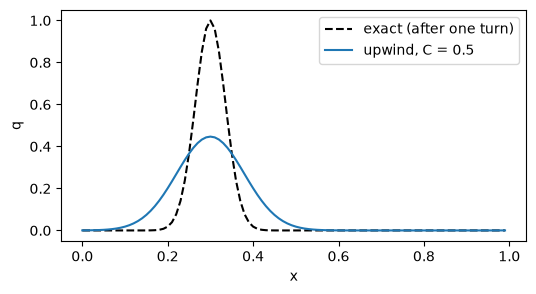

In [2]:
nx = 100
x = np.linspace(0, 1, nx, endpoint=False)
dx = x[1] - x[0]
q0 = np.exp(-(((x - 0.3) / 0.05) ** 2))


def upwind(q, courant, nsteps):
    states = [q.copy()]
    for _ in range(nsteps):
        q = q - courant * (q - np.roll(q, 1))
        states.append(q.copy())
    return np.array(states)


courant = 0.5
nsteps = int(round(1 / (courant * dx)))
states = upwind(q0, courant, nsteps)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(x, q0, "k--", label="exact (after one turn)")
ax.plot(x, states[-1], label=f"upwind, C = {courant}")
ax.set_xlabel("x")
ax.set_ylabel("q")
ax.legend()
fig.savefig(IMG / "advection-final.png", dpi=150, bbox_inches="tight")
plt.show()

The same run as a GIF.

In [3]:
fig, ax = plt.subplots(figsize=(6, 3), dpi=80)
(line,) = ax.plot(x, q0)
ax.set_ylim(-0.1, 1.1)
ax.set_xlabel("x")
ax.set_ylabel("q")


def update(n):
    line.set_ydata(states[n])
    ax.set_title(f"step {n}")
    return (line,)


animation = FuncAnimation(fig, update, frames=range(0, nsteps + 1, 4))
animation.save(IMG / "advection.gif", writer=PillowWriter(fps=15))
plt.close(fig)

An interactive figure with a slider on the Courant number, saved as a standalone HTML file.

In [4]:
courants = [0.1, 0.25, 0.5, 0.75, 1.0]
fig = go.Figure()
for c in courants:
    final = upwind(q0, c, int(round(1 / (c * dx))))[-1]
    fig.add_trace(go.Scatter(x=x, y=final, name=f"upwind, C = {c}", visible=(c == 0.5)))
fig.add_trace(go.Scatter(x=x, y=q0, name="exact", line=dict(dash="dash", color="black")))

steps = [
    dict(label=str(c), method="update", args=[{"visible": [c == d for d in courants] + [True]}])
    for c in courants
]
fig.update_layout(
    sliders=[dict(active=2, currentvalue={"prefix": "Courant number: "}, pad={"t": 50}, steps=steps)],
    xaxis_title="x",
    yaxis_title="q",
    height=440,
    margin=dict(t=30),
)
fig.write_html(PLOTLY / "advection.html", include_plotlyjs="cdn")